In [104]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
try:
    import geopandas as gpd
except ImportError:
    print("Geopandas is not installed. Attempting to install it now...")
    !pip install geopandas
    import geopandas as gpd

DO_WITHIN_BUFF = False
PLOT_CRS = 3857
CALC_CRS = "EPSG:32612"
SAMPLE_RATE = .1

# Geospatial Basics

<b>Note on Data:</b> I am dropping the neighborhoods data from this dataset because we will find it later, using spatial data. 

## Geopandas

To do most spatial things we use a library called geopandas, which is basically pandas plus some spatial functionality. Most things work exactly like regular pandas, and the two are largely interchangeable. The main difference is that geopandas has a special column called `geometry` which contains the spatial data. This column defines the "geometry" or the specific area in space, that the row represents - be it a point, a line, or a polygon. We will load or convert data into a new type of dataframe called a `GeoDataFrame`. 

The geometry column is a special type of data called a `GeoSeries`, which is again a special revision built on a Series. Each object can be a point, line, or polygon. Geopandas has a lot of built-in functionality for working with these geometric objects, including methods for calculating area, distance, and intersection. For our purposes, these operations mostly work exactly how you'd expect them to, with the geometric calculations being done invisibly in the background.

In [105]:
bylaw_data_url = "https://jrssbcrsefilesnait.blob.core.windows.net/3950data1/Bylaw_Complaint_Details_20261119.csv"
save_file_path = "data/zz_bylaw_complaints.csv"

# Check if we have the file, if not, download it. 
# the zz preface ensures it'll not be included in any github actions
if not os.path.exists(save_file_path):
    print("Downloading file...")
    df = pd.read_csv(bylaw_data_url)
    df.to_csv(save_file_path, index=False)
else:
    print("File already exists, loading from disk...")
    df = pd.read_csv(save_file_path)
df.drop(columns=['Neighbourhood', 'Neighbourhood ID', 'Count'], inplace=True)
df["Was Cannabis Involved"] = df["Was Cannabis Involved"].map({"Yes": 1, "No": 0})
df["Officer Initiated"] = df["Officer Initiated"].map({"Y": 1, "N": 0})

# Sample the data
df = df.sample(frac=SAMPLE_RATE)

df.head()

File already exists, loading from disk...


/tmp/ipykernel_1239/989347938.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Neighbourhood', 'Neighbourhood ID', 'Count'], inplace=True)


,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,Latitude,Longitude,Location
358494,91282346311351808,2014,12-Dec,"Dec 20, 2014",Property - Snow/Ice,Snow/Ice On Walk,0,0,Completed,STRATHEARN DRIVE NW,53.536403,-113.461194,"(53.53640293704875, -113.46119378088196)"
462853,109200014690662512,2020,09-Sep,"Sep 08, 2020",Other,General,0,0,Completed,123 STREET NW,53.586050,-113.533501,"(53.58605036070478, -113.53350105185115)"
309609,40852438005492784,2015,01-Jan,"Jan 22, 2015",Property - Snow/Ice,Snow/Ice On Walk,0,1,Completed,164 STREET NW,53.555220,-113.601980,"(53.55522033541407, -113.6019801488618)"
94530,16943287365847378,2024,08-Aug,"Aug 07, 2024",Business Licensing,Unlicenced business,0,0,Completed,35 AVENUE NW,53.468922,-113.357044,"(53.46892242853355, -113.35704443634775)"
35297,58268100782627096,2026,07-Jul,"Jul 28, 2026",Property - Nuisance,Weeds,0,0,Completed,137 STREET NW,53.612982,-113.557032,"(53.612981696699705, -113.55703236199979)"


## Geometries

The first thing that we can do is to define the geometry for our dataset. The 'geometry' column is a special column that contains the geometric info for whatever the data represents. For ours, we have a list of bylaw infractions from the city, so we want the geometry column to be the location of the infraction. In other situations it might be the area of a neighborhood, or the location of a business, or the land of a park. Basicially whatever the "mapped thing" is for this dataset. 

Note that we aren't strictly limited to one geometric thing per row, we can have as many columsn holding geometric data as we want, the 'geometry' column is the default "shape" of the row of data, and if we map it, that's what we get. 

### Creating Geometry Columns

Our data will have something that defines it's spatial data, generally either latitude/longitude, a "polygon" column representing a region, or a pre-defined "point" that may or may not be automatically interpreted correctly. Our data has a "location" column that has the pont information, but we'd need to do some work to make geopandas understand it, it will give an error if fed that column as geometry directly. Instead, we can use the latitude and longitude columns to create a new geometry column. "Point" columns that are loaded from csvs often fail by default, usually the data has latitude and longitude, so I find it easiest to just use those. Polygon, or areas, usually get read correctly, in my experience - if they don't that can usually be solved with some data cleanup, likely using another core library called shapely (I've had to do it before, it isn't really hard, but a bit annoying. We can figure it out as needed if it comes up).

We can declare the geometry column when creating the GeoDataFrame, set it after the fact, or even change it (for example, if we had multiple spatial columns and wanted to switch between them).

### Coordinate Systems

The details of this are beyond what we care about, but there are basically several different ways encode spatial data, and they are not all compatible with each other. We can think of these kind of like different map projections - they all show the same base information, but represent it differently. This is something that comes from whover made the dataset, for ours, I read that LL-WGS84 is the system used from the data dictionary. 

One important note is that there are two different types of coordinate systems, geographic and projected. Geographic coordinate systems use latitude and longitude to define locations on the earth's surface, while projected coordinate systems use a flat, two-dimensional plane to represent the earth's surface. For this example we'll use two common systems, LL-WGS84 (EPSG:4326) and Web Mercator (EPSG:3857). The differences become important when we are doing calculations, like distances - for accurate values we want to use one of the ones that works in "flat meters" rather than "degrees of latitude/longitude". The to_crs() function can be used to convert between coordinate systems as needed.  

![CRS Systems](images/crs.png)

For things to work accurately, we need to tell our data what coordinate system it is using. I looked up the EPSG code for LL-WGS84, and it is 4326. So we will use that to define our geometry column.

In [106]:
df.head(5)

,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,Latitude,Longitude,Location
358494,91282346311351808,2014,12-Dec,"Dec 20, 2014",Property - Snow/Ice,Snow/Ice On Walk,0,0,Completed,STRATHEARN DRIVE NW,53.536403,-113.461194,"(53.53640293704875, -113.46119378088196)"
462853,109200014690662512,2020,09-Sep,"Sep 08, 2020",Other,General,0,0,Completed,123 STREET NW,53.586050,-113.533501,"(53.58605036070478, -113.53350105185115)"
309609,40852438005492784,2015,01-Jan,"Jan 22, 2015",Property - Snow/Ice,Snow/Ice On Walk,0,1,Completed,164 STREET NW,53.555220,-113.601980,"(53.55522033541407, -113.6019801488618)"
94530,16943287365847378,2024,08-Aug,"Aug 07, 2024",Business Licensing,Unlicenced business,0,0,Completed,35 AVENUE NW,53.468922,-113.357044,"(53.46892242853355, -113.35704443634775)"
35297,58268100782627096,2026,07-Jul,"Jul 28, 2026",Property - Nuisance,Weeds,0,0,Completed,137 STREET NW,53.612982,-113.557032,"(53.612981696699705, -113.55703236199979)"


/tmp/ipykernel_1239/216747907.py:3: Pandas4Warning: The inplace keyword in GeoDataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gdf.dropna(subset=['geometry'], inplace=True)  # Drop rows where geometry is NaN


Mapping using CRS: EPSG:4326


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

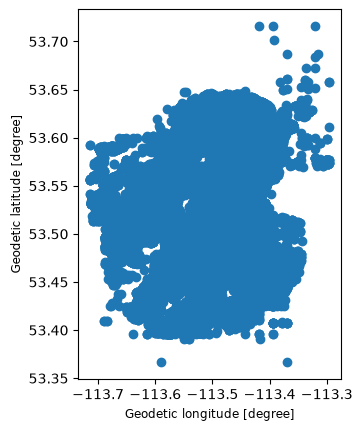

In [107]:
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['Longitude'], df['Latitude']))
gdf.set_crs("EPSG:4326", inplace=True)
gdf.dropna(subset=['geometry'], inplace=True)  # Drop rows where geometry is NaN
print("Mapping using CRS:", gdf.crs)
gdf.plot()

### More Mapping

That plot of the points looks pretty bad, we don't have any map info other than the locations of the dots. We can add a basemap to the plot to make it look better. To do this, we will use the contextily library, which is a library that adds basemaps to geopandas plots.

The reprojection here was because the 

In [108]:
try:
    import contextily as ctx
except ImportError:
    print("Contextily is not installed. Attempting to install it now...")
    !pip install contextily
    import contextily as ctx

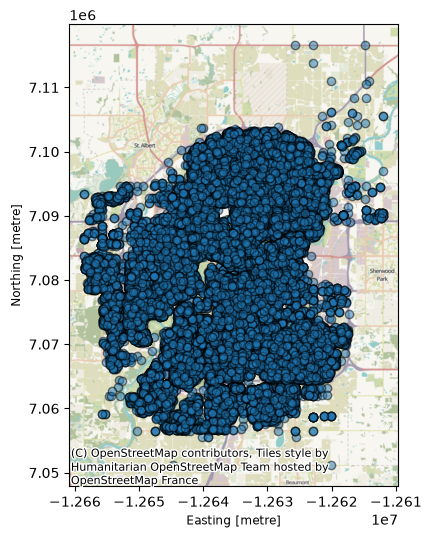

In [109]:
gdf_mercator = gdf.to_crs(PLOT_CRS)  # Convert to Web Mercator for mapping
ax = gdf_mercator.plot(alpha=0.5, edgecolor='k', figsize=(6, 6))
ctx.add_basemap(ax)

## Adding Layers Manually

In [110]:
gdf_hoods = gpd.read_file("data/edmontonHoods.kml")
gdf_hoods.set_crs("EPSG:4326", inplace=True)
gdf.set_geometry("geometry")
gdf_hoods.head()

,id,Name,description,timestamp,begin,end,altitudeMode,tessellate,extrude,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,geometry
0,None,ABBOTTSFIELD,"Abbottsfield was once owned by E.F. Carey, one...",NaT,NaT,NaT,None,-1,0,-1,NaN,None,2010,Abbottsfield,,,"MULTIPOLYGON (((-113.38763 53.57613, -113.3888..."
1,None,ALBANY,,NaT,NaT,NaT,None,-1,0,-1,NaN,None,3460,Albany,,,"MULTIPOLYGON (((-113.56025 53.6316, -113.56227..."
2,None,ALBERTA AVENUE,One of the city's older residential neighbourh...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,1010,Alberta Avenue,,,"MULTIPOLYGON (((-113.49226 53.57662, -113.4922..."
3,None,ALBERTA PARK INDUSTRIAL,This non-residential neighbourhood is largely ...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,4010,Alberta Park Industrial,,,"MULTIPOLYGON (((-113.59041 53.56654, -113.5904..."
4,None,ALDERGROVE,"Planned in the 1970s, this area's multi-family...",NaT,NaT,NaT,None,-1,0,-1,NaN,None,4020,Aldergrove,,,"MULTIPOLYGON (((-113.65209 53.5195, -113.65209..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

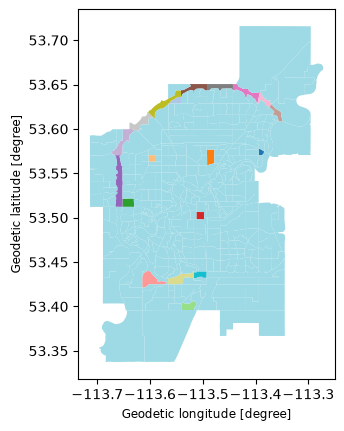

In [111]:
gdf_hoods.plot("Name")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

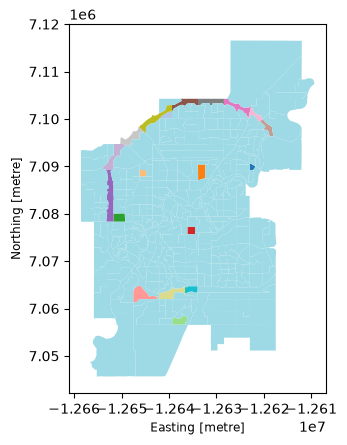

In [112]:
gdf_hoods_mercator = gdf_hoods.to_crs(PLOT_CRS)  # Convert to Web Mercator for mapping
gdf_hoods_mercator.plot("Name")

And together. 

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

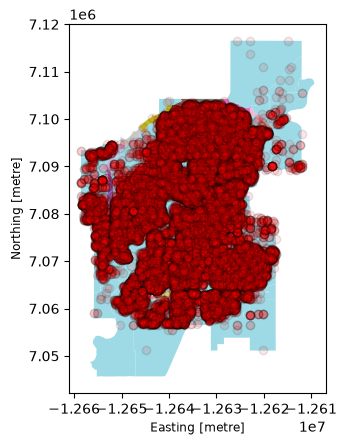

In [113]:
fig, ax = plt.subplots()
gdf_hoods_mercator.plot("Name", ax=ax)
gdf_mercator.plot(ax=ax, alpha=0.1, edgecolor='k', color='red')

## Spatial Joins

We can use the data plotted on the map above to do a join, a spatial join. The difference in a spatial join is that rather than having some key value to join on, we are joining based on the spatial relationship between the two datasets. The spatial processing in geopandas will automatically do the math for the join for us. The join types are also different from the regular left/right/inner joins, we have "intersects", "contains", and "within" as the join types.

![Spatial Join](images/spatial_join.avif)

These spatial joins replace the key with some spatial calculation, typically something like what we'll do, is this point in this neighborhood? So, we can effectively add the neighborhood column to the original dataset by looking up which neighborhood geometry contains the point geometry for each row in the original dataset.

<b>Note:</b> The spatial join will only work correctly if both datasets are in the same coordinate system. We also lose the right side of the join's geometry column when geopandas does the join, so the loop is just to restore it. 

### Keep 'em Separated

In most cases, it is easier to keep the datasets separate if we are dealing with multiple spatial datasets, and just join as needed. The geopandas dataframe is generally setup to default to one geometry column being the "main thing". We can construct a dataset with many spatial columns, but it is likely to be more annoying than having separate dataframes. 

In [114]:
# Reproject the GeoDataFrames to a common CRS for spatial join
gdf_mercator.to_crs(PLOT_CRS, inplace=True)
gdf_hoods_mercator.to_crs(PLOT_CRS, inplace=True)
df_w_hoods = gpd.sjoin(gdf_mercator, gdf_hoods_mercator, how="left", predicate='within')
hood_geometries = df_w_hoods["index_right"].map(gdf_hoods_mercator.geometry)
df_w_hoods["hood_geometry"] = gpd.GeoSeries(
    hood_geometries.tolist(),
    index=df_w_hoods.index,
    crs=gdf_hoods_mercator.crs,
)
df_w_hoods.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 68981 entries, 358494 to 592552
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Row ID                 68981 non-null  object        
 1   Year                   68981 non-null  int64         
 2   Month                  68981 non-null  str           
 3   Date Created           68981 non-null  str           
 4   Complaint Category     68981 non-null  str           
 5   Type of Complaint      68981 non-null  str           
 6   Was Cannabis Involved  68981 non-null  int64         
 7   Officer Initiated      68981 non-null  int64         
 8   Infraction Status      68981 non-null  str           
 9   Full Name of Street    68981 non-null  str           
 10  Latitude               68981 non-null  float64       
 11  Longitude              68981 non-null  float64       
 12  Location               68981 non-null  str         

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

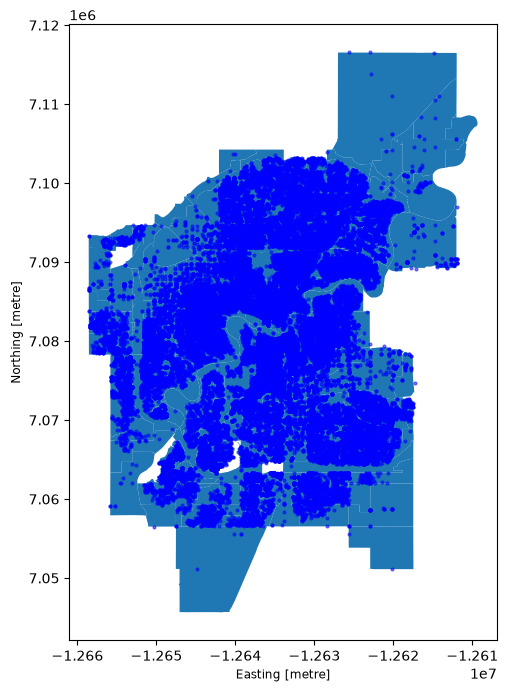

In [115]:
fig, ax = plt.subplots(figsize=(8, 8))
df_w_hoods["hood_geometry"].dropna().drop_duplicates().plot(ax=ax)
df_w_hoods["geometry"].plot(ax=ax, color="blue", markersize=4, alpha=0.5)

## Modelling

Ok, let's use this to make some predictive models. 

### Spatial Features

We can use the latitude and longitude directly, they are just numbers, but in most cases these wouldn't make good features. They would basically give us the E/W and N/S position of each incident, but I doubt that's super useful. If we were building a model to aim artillery shots, then having latitude and longitude may be very useful, but in most cases, we want to *construct* new features from the spatial data. 

In most cases, the types of things we'd create from spatial data are things like:
<ul>
    <li> Distance to some point of interest.</li>
    <li> Number of points within some distance/region.</li>
    <li> Whether the point is within some region.</li>
    <li> Closest neighbor distance.</li>
</ul>

Now, our specific set of examples here are strictly for demonstration purposes, these probably won't result in an incredible model, but they will show how to use spatial data to create features.


### Predict Cannabis

One of the values in our dataset is a binary value on if the infraction involved cannabis or not. We can use this as a target variable for a classification model.

### Baseline Model

I'm going to predict if a call was "Officer Initiated" or not, so a binary classification. 

For the baseline model, I'll use the latitude and longitude directly, and see how well that does. Note that I don't think these 311 calls are the easiest thing to predict in the best of times. 

I'm also going to define a subset of features to use for all of these models. In reality, we'd want to do some tuning and testing here, but we won't do that outside of spatial things. 

In [116]:
df_w_hoods["Officer Initiated"].value_counts()

Officer Initiated
0    50921
1    18060
Name: count, dtype: int64

In [117]:
predCol = "Officer Initiated"

numFeatures = ["Latitude", "Longitude", "Year"]
catFeatures = ["Month", "Complaint Category", "Type of Complaint"]
pred_cols = numFeatures + catFeatures
df_w_hoods = df_w_hoods.dropna(subset=pred_cols)  # Drop rows with NaN in any of the predictor columns

y1 = df_w_hoods[predCol]
X1 = df_w_hoods[pred_cols]
print("Features shape:", X1.shape)
print("Target shape:", y1.shape)

Features shape: (68981, 6)
Target shape: (68981,)


#### Helper Function

If you're a good programmer, you're lazy. I have to make basically the same pipeline over and over, so I will make a function to help me. This type of thing is often a good idea, for a few reasons:
<ul>
<li> It saves time, I don't have to write the same code over and over.</li>
<li> It saves space in code, making it easier to read and understand.</li>
<li> It makes it easier to change things, if I want to change the model, I can do it in one place, rather than having to change it in multiple places.</li>
<li> It makes it easier to test and maintain - we only have one operation, not 8 versions of it. We can be more sure we're right. </li>
<li> It isn't always relevant, but it is "more shareable" - we can deploy it to other locations, share it with others, etc... </li>
</ul>

In some neural network model testing setups, a slightly more complex version of this is how we'd provide the model for the testing framework. 

<b>In this specific case, I can't just reuse anything from model to model, and not just dude to feature differences. Some steps, like imputation, learn from the data (in their 'fit' step), so they aren't portable to other datasets, we have to refit. </b>


In [118]:
def makePipe(numFeatLabels, catFeatLabels, doRegression=False):
    # Preprocessing for numerical data
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Preprocessing for categorical data
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numFeatLabels),
            ('cat', categorical_transformer, catFeatLabels)
        ])

    # Create the pipeline with a classifier
    if doRegression:
        clf = Pipeline(steps=[('preprocessor', preprocessor),
                              ('regressor', LinearRegression())])
    else:
        clf = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', LogisticRegression(max_iter=1000))])
    
    return clf

Baseline model accuracy: 0.7589


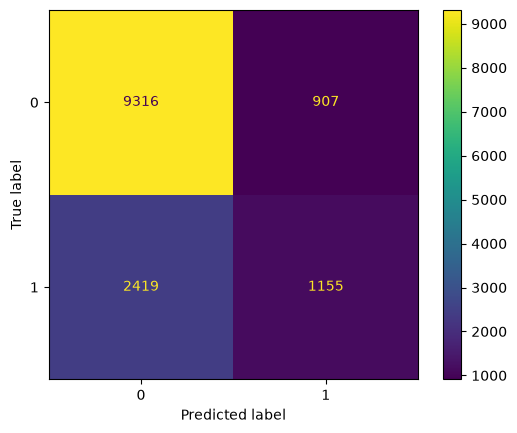

In [119]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y1, test_size=0.2)

pipe1 = makePipe(numFeatures, catFeatures)

pipe1.fit(X_train1, y_train1)
predictions1 = pipe1.predict(X_test1)
accuracy1 = (predictions1 == y_test1).mean()
print(f"Baseline model accuracy: {accuracy1:.4f}")
# confusion matrix
cm1 = confusion_matrix(y_test1, predictions1)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=pipe1.classes_)
disp1.plot()

### Try Some Variations

Now we can try to make some models using spatial features and try using them in models. This specific dataset doesn't make for the most dramatic results, but the processes are the same no matter the data. 

#### Distance from Police

We can use the police station locations to create a feature that is the distance from each infraction to the nearest police station. 

In [120]:
stations = pd.read_csv("data/Police_Stations.csv")
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations["LONGITUDE"], stations["LATITUDE"]),
    crs="EPSG:4326",
)
stations = stations.dropna(subset=['geometry'])  # Drop rows where geometry is NaN
stations.to_crs(PLOT_CRS, inplace=True)  # Set the CRS for stations to Web Mercator for mapping
stations.head()

,NAME,ADDRESS,LATITUDE,LONGITUDE,LOCATION,Geometry Point,geometry
0,POLICE SERVICES - NORTHEAST DIVISION,14203 - 50 STREET NW,53.605040,-113.417301,"(53.60503991263262, -113.41730142003281)",POINT (-113.41730142003281 53.60503991263262),POINT (-12625556.241 7095707.618)
1,ROYAL CANADIAN MOUNTED POLICE,11136 - 109 STREET NW,53.559845,-113.509119,"(53.55984492708671, -113.50911929739945)",POINT (-113.50911929739945 53.55984492708671),POINT (-12635777.361 7087233.008)
2,POLICE SERVICES - WEST DIVISION,16505 - 100 AVENUE NW,53.538808,-113.606742,"(53.538808087195235, -113.60674227242592)",POINT (-113.60674227242592 53.538808087195235),POINT (-12646644.7 7083291.432)
3,RCMP K DIVISION,11136 - 109 STREET NW,53.559845,-113.509119,"(53.55984492708671, -113.50911929739945)",POINT (-113.50911929739945 53.55984492708671),POINT (-12635777.361 7087233.008)
4,POLICE SERVICES - SOUTHEAST DIVISION,104 - YOUVILLE DRIVE EAST NW,53.460001,-113.426714,"(53.46000050776202, -113.42671444062009)",POINT (-113.42671444062009 53.46000050776202),POINT (-12626604.094 7068543.007)


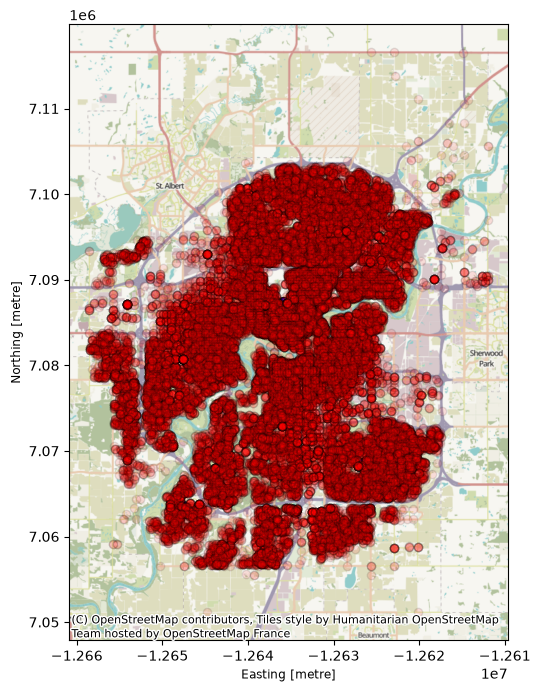

In [121]:
ax = stations.plot(color='blue', markersize=50, alpha=0.7, edgecolor='k', figsize=(8, 8))
ax = gdf_mercator.plot(ax=ax, alpha=0.1, edgecolor='k', color='red')
ctx.add_basemap(ax)

### Feature Construction - Distance

Distance is probably the most common type of feature that we would construct from spatial data. We can use the distance between points, or the distance from a point to some other location like the city center, a police station, or another neighborhood. As long as we have geometries defined, we can use the distance function to calculate the distance between two geometries. 

We can make a simple function to calculate the distances, as long as our datasets have their geometries set and tehy are in the same coordinate system, we need to do very little. If we need to use some specific location to calculate from, we can just create a new point or polygon geometry and use that as the "other" dataset.

The crs system used for the distance calculations is important, we need to make sure that both datasets are in the same coordinate system, and that the coordinate system is one that makes sense for distance calculations. The default crs for geopandas is EPSG:4326, which is a geographic coordinate system, and not a projected coordinate system. This means that the units are in degrees, and not in meters. For distance calculations, we want to use a projected coordinate system, so we will convert our datasets to EPSG:32612, which is a projected coordinate system that uses meters as units.

In [122]:
def getClosestStationDistance(row, stations_gdf):
    if row.geometry is None or row.geometry.is_empty:
        return None
    row_projected = gpd.GeoSeries([row.geometry], crs=df_w_hoods.crs).to_crs(CALC_CRS).iloc[0]
    stations_projected = stations_gdf.to_crs(CALC_CRS)  # Project the stations GeoDataFrame to the calculation CRS
    distances = stations_projected.distance(row_projected)
    smallest_distance = distances.min()
    return smallest_distance


# Add a new column for the closest station distance and name
df_w_hoods["closest_station_distance"] = df_w_hoods.apply(getClosestStationDistance, axis=1, stations_gdf=stations)

df_w_hoods.head()

,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,...,extrude,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,hood_geometry,closest_station_distance
358494,91282346311351808,2014,12-Dec,"Dec 20, 2014",Property - Snow/Ice,Snow/Ice On Walk,0,0,Completed,STRATHEARN DRIVE NW,...,0.0,-1.0,NaN,None,6710,Strathearn,,,"MULTIPOLYGON (((-12631594.875 7082178.815, -12...",2008.580344
462853,109200014690662512,2020,09-Sep,"Sep 08, 2020",Other,General,0,0,Completed,123 STREET NW,...,0.0,-1.0,NaN,None,3070,Calder,,,"MULTIPOLYGON (((-12639161.377 7091746.466, -12...",859.667266
309609,40852438005492784,2015,01-Jan,"Jan 22, 2015",Property - Snow/Ice,Snow/Ice On Walk,0,1,Completed,164 STREET NW,...,0.0,-1.0,NaN,None,4290,Mayfield,,,"MULTIPOLYGON (((-12645762.672 7087061.377, -12...",1853.601233
94530,16943287365847378,2024,08-Aug,"Aug 07, 2024",Business Licensing,Unlicenced business,0,0,Completed,35 AVENUE NW,...,0.0,-1.0,NaN,None,6443,Tamarack,,,"MULTIPOLYGON (((-12618812.702 7067434.775, -12...",4732.035110
35297,58268100782627096,2026,07-Jul,"Jul 28, 2026",Property - Nuisance,Weeds,0,0,Completed,137 STREET NW,...,0.0,-1.0,NaN,None,3150,Cumberland,,,"MULTIPOLYGON (((-12640134.001 7096126.92, -126...",2521.146090


### Model with Distance

We can use that model as a feature, and see if it improves the model.

In [123]:
numFeatures2 = [feature for feature in numFeatures if feature not in {"Latitude", "Longitude"}]
#numFeatures2 = [feature for feature in numFeatures]
numFeatures2.append("closest_station_distance")
pred_cols2 = numFeatures2 + catFeatures

y2 = df_w_hoods[predCol]
X2 = df_w_hoods[pred_cols2]
print("Features shape:", X2.shape)


Features shape: (68981, 5)


Model with distance feature accuracy: 0.7602


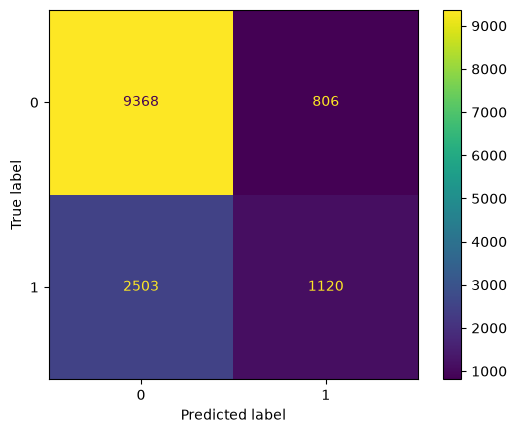

In [124]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2)
pipe2 = makePipe(numFeatures2, catFeatures)

pipe2.fit(X_train2, y_train2)
predictions2 = pipe2.predict(X_test2)
accuracy2 = (predictions2 == y_test2).mean()
print(f"Model with distance feature accuracy: {accuracy2:.4f}")
# confusion matrix
cm2 = confusion_matrix(y_test2, predictions2)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=pipe2.classes_)
disp2.plot()

### Feature Construction - Aggregation

We can also use the spatial data to construct features that are aggregated over some region. For example, we can count the number of infractions within each neighborhood, and use that as a feature in our model.

This is most useful in a situation like this, where we are taking points and sorting them into groups, like neighborhoods. 

#### Per Neighborhood Prediction

<b>Note:</b> The reality of this prediction is not going to be good. We only have a handful of neighborhoods and just a few, not super relevant, per-neighborhood features to use in the model. If we actually want to use this, we'd need to go find more data that is per-neighborhood and build a reasonable feature set to predict the number of infractions. This is just for the sake of manipulating the spatial data. 

In [125]:
hood_pred_cols = ["hood_geometry", "Row ID", "Name","Was Cannabis Involved", "Officer Initiated"]
hoodDF = df_w_hoods[hood_pred_cols].dropna(subset=hood_pred_cols)
hoodDF.set_geometry("hood_geometry", inplace=True)
hoodDF = hoodDF.groupby("Name").agg({"Row ID": "count", "Was Cannabis Involved": "sum", "Officer Initiated": "sum"}).rename(columns={"Row ID": "Count"}).sort_values(by="Count", ascending=False)
hoodDF = hoodDF.reset_index()
hoodDF = hoodDF.join(gdf_hoods_mercator.set_index("Name")[["geometry"]], on="Name", how="left")
hoodDF = gpd.GeoDataFrame(hoodDF, geometry="geometry", crs=gdf_hoods_mercator.crs)
hoodDF.sample(10)

,Name,Count,Was Cannabis Involved,Officer Initiated,geometry
145,OLESKIW,172,0,37,"MULTIPOLYGON (((-12646219.443 7074429.811, -12..."
192,ERMINESKIN,124,0,9,"MULTIPOLYGON (((-12636472.097 7068788.857, -12..."
123,BLUE QUILL,196,0,63,"MULTIPOLYGON (((-12638299.275 7068786.299, -12..."
83,GREENFIELD,254,0,71,"MULTIPOLYGON (((-12638641.028 7069938.306, -12..."
256,BONAVENTURE INDUSTRIAL,68,1,13,"MULTIPOLYGON (((-12643066.631 7091713.362, -12..."
116,LAURIER HEIGHTS,213,0,48,"MULTIPOLYGON (((-12640625.713 7079105.587, -12..."
183,STRATHCONA JUNCTION,128,0,24,"MULTIPOLYGON (((-12634491.826 7079408.655, -12..."
271,SIFTON PARK,57,0,11,"MULTIPOLYGON (((-12623906.509 7093781.958, -12..."
196,TRUMPETER AREA,118,0,33,"MULTIPOLYGON (((-12654213.811 7094305.087, -12..."
206,CROMDALE,110,0,29,"MULTIPOLYGON (((-12631492.441 7087210.459, -12..."


In [126]:
hoodDF["Area"] = hoodDF.to_crs(CALC_CRS).area
hoodDF["Circumference"] = hoodDF.to_crs(CALC_CRS).length
hoodDF["Compactness"] = hoodDF["Circumference"] / hoodDF["Area"]
hoodDF["Closest Station Distance"] = hoodDF.apply(lambda row: getClosestStationDistance(row, stations), axis=1)
hoodDF.sort_values("Closest Station Distance", ascending=True).head()

,Name,Count,Was Cannabis Involved,Officer Initiated,geometry,Area,Circumference,Compactness,Closest Station Distance
166,MILLER,146,0,43,"MULTIPOLYGON (((-12625533.883 7096405.94, -126...",8.268232e+05,4141.280339,0.005009,0.0
18,WINDERMERE,557,0,143,"MULTIPOLYGON (((-12646458.09 7066240.088, -126...",4.774027e+06,14234.573112,0.002982,0.0
67,KENSINGTON,287,0,87,"MULTIPOLYGON (((-12638652.398 7094659.62, -126...",1.325468e+06,4879.784591,0.003682,0.0
98,PRINCE RUPERT,232,0,47,"MULTIPOLYGON (((-12636700.085 7088129.174, -12...",1.145019e+06,5258.249329,0.004592,0.0
25,BOYLE STREET,484,1,142,"MULTIPOLYGON (((-12632857.787 7085275.807, -12...",8.813836e+05,5060.696362,0.005742,0.0


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

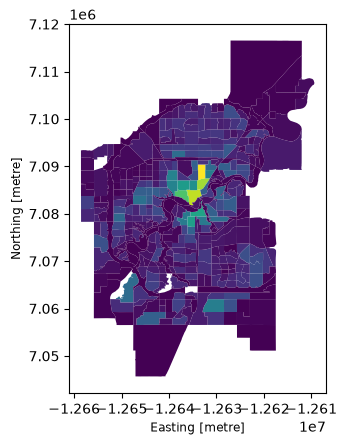

In [127]:
hoodDF.plot("Count")

In [128]:
hoodPredCols = ["Area", "Closest Station Distance", "Was Cannabis Involved", "Officer Initiated"]
yHoods = hoodDF["Count"]
Xhoods = hoodDF[hoodPredCols]

X_trainH, X_testH, y_trainH, y_testH = train_test_split(Xhoods, yHoods, test_size=0.2)

In [129]:
pipeHood = makePipe(hoodPredCols, [], doRegression=True)

pipeHood.fit(X_trainH, y_trainH)
hoodPreds = pipeHood.predict(X_testH)
hoodScore = pipeHood.score(X_testH, y_testH)
print(f"Hood model R^2 score: {hoodScore:.4f}")

Hood model R^2 score: 0.7701


### Stats Time - What Does it Mean?

We have a model that is pretty accurate at predicting this, what does it mean? We can conclude a few things:
<ul>
<li> Our sample size is very small, so we shouldn't expect to be able to rely on the results too much. </li>
<li> It appears that the features of "Area", "Closest Station Distance", "Was Cannabis Involved", "Officer Initiated" are all useful in predicting the number of infractions in a neighborhood. </li>
</ul>

Does this make sense? Maybe, to some degree. I'd wager that the combination of "Officer Initiated" as well as "Distance from Station", and maybe "Area" are going to largely be proxies for what neighborhoods are more likely to have police presence, which probably also tend to skew higher. We'd need to investigate further, but I suspect that there are other data points for neighborhood that we don't have with a higher predictive value, and our info is kind of a proxy for that.

### Feature Construction - Things Within

Another type of feature that is useful is to count the number of things within some distance. For the "within" part we can either define a buffer, which is basically a virtual circle N-distance from another point (or geometry), or we can use an existing poylgon like a neighborhood. In code, this is pretty simple, as long as we have geomerties defined, the 'within' function will do the work for us.

#### Buffers and Density Calculations

Let's try adding a feature to the dataset that measures the relative density of infractions. Since we want this on a per-infraction basis, we want to decide on a way to measure how many other infractions are "nearby". This is 100% arbitrary, we'd need some domain knowledge to make actual real decisions of what "nearby" means. 

In [130]:

def infractionsWithin(row, otherEvents, distance=100):
    if row.geometry is None or row.geometry.is_empty:
        return 0
    row_projected = gpd.GeoSeries([row.geometry], crs=df_w_hoods.crs).to_crs(CALC_CRS).iloc[0]
    otherEvents_projected = otherEvents.to_crs(CALC_CRS)  #
    buffer = row_projected.buffer(distance)
    count = otherEvents_projected[otherEvents_projected.geometry.within(buffer)].shape[0]
    return count
    
if DO_WITHIN_BUFF:
    infraction_radius = 100  # meters
    df_w_hoods["infractions_within_radius"] = df_w_hoods.apply(infractionsWithin, axis=1, otherEvents=df_w_hoods, distance=infraction_radius)
df_w_hoods.sort_values("closest_station_distance", ascending=True).head()


,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,...,extrude,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,hood_geometry,closest_station_distance
176895,22454509581547448,2024,07-Jul,"Jul 15, 2024",Property - Nuisance,Weeds,0,0,Completed,165 STREET NW,...,0.0,-1.0,NaN,None,4180,Glenwood,,,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",54.221758
145501,22108326794028900,2020,05-May,"May 01, 2020",Property - Maintenance,Graffiti,0,0,Completed,96 STREET NW,...,0.0,-1.0,NaN,None,1020,Boyle Street,,,"MULTIPOLYGON (((-12632857.787 7085275.807, -12...",63.535195
350358,112470576707954400,2024,02-Feb,"Feb 08, 2024",Conduct - Public Places,Illegal camping,0,0,Completed,96 STREET NW,...,0.0,-1.0,NaN,None,1020,Boyle Street,,,"MULTIPOLYGON (((-12632857.787 7085275.807, -12...",63.535195
23071,58321091176456616,2026,10-Oct,"Oct 01, 2026",Business Licensing,Unlicenced business,0,1,Completed,103A AVENUE NW,...,0.0,-1.0,NaN,None,1020,Boyle Street,,,"MULTIPOLYGON (((-12632857.787 7085275.807, -12...",65.740526
654376,392664402645968768,2023,06-Jun,"Jun 14, 2023",Property - Nuisance,Nuisance Property,0,0,Completed,103A AVENUE NW,...,0.0,-1.0,NaN,None,1020,Boyle Street,,,"MULTIPOLYGON (((-12632857.787 7085275.807, -12...",65.740526


#### Smaller Example - Police Stations Within Buffer

This example is more practial to run, but not as useful. This will take a buffer distance around each point, and tabulate the number of police stations within that buffer. This is one pretty common type of feature we'd create. 

In [131]:
def policeStationsWithin(row, stations_list, distance=1000):
    if row.geometry is None or row.geometry.is_empty:
        return 0
    row_projected = gpd.GeoSeries([row.geometry], crs=df_w_hoods.crs).to_crs(CALC_CRS).iloc[0]
    stations_projected = stations_list.to_crs(CALC_CRS)  # Project
    buffer = row_projected.buffer(distance)
    count = stations_projected[stations_projected.geometry.within(buffer)].shape[0]
    return count

df_w_hoods["police_stations_within_radius"] = df_w_hoods.apply(policeStationsWithin, axis=1, stations_list=stations, distance=3000)
df_w_hoods.sort_values("police_stations_within_radius", ascending=False).head()

,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,...,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,hood_geometry,closest_station_distance,police_stations_within_radius
465138,16115007344663048,2019,11-Nov,"Nov 04, 2019",Noise,Noise,0,0,Completed,111 STREET NW,...,-1.0,NaN,None,1150,Oliver,,,"MULTIPOLYGON (((-12635857.069 7083575.54, -126...",2102.982828,5
98577,19146591257719952,2017,03-Mar,"Mar 09, 2017",Property - Nuisance,Nuisance Property,0,1,Completed,116 STREET NW,...,-1.0,NaN,None,1150,Oliver,,,"MULTIPOLYGON (((-12635857.069 7083575.54, -126...",1877.190164,5
487439,34990646329553168,2024,05-May,"May 01, 2024",Property - Nuisance,Nuisance Property,0,0,Completed,97 STREET NW,...,-1.0,NaN,None,1140,McCauley,,,"MULTIPOLYGON (((-12633409.49 7085026.777, -126...",1150.871661,5
219555,19410129945862808,2020,02-Feb,"Feb 03, 2020",Property - Maintenance,Graffiti,0,0,Completed,111 STREET NW,...,-1.0,NaN,None,1090,Downtown,,,"MULTIPOLYGON (((-12636109.257 7083797.966, -12...",1304.360936,5
219555,19410129945862808,2020,02-Feb,"Feb 03, 2020",Property - Maintenance,Graffiti,0,0,Completed,111 STREET NW,...,-1.0,NaN,None,1180,Queen Mary Park,,,"MULTIPOLYGON (((-12635699.401 7085062.295, -12...",1304.360936,5


### Model with Police Stations Within Buffer

This is not a great example in terms of feature independence, as we have two metrics that both measure police station distance related things. For using the spatial data though, this is good enough. 

Model with distance and within radius features accuracy: 0.7647


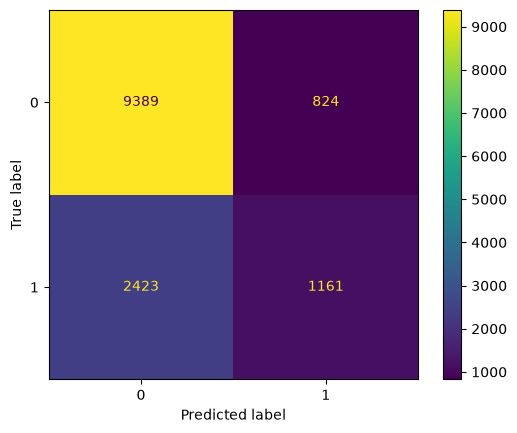

In [132]:
numFeatures3 = numFeatures2 + ["police_stations_within_radius"]

y3 = df_w_hoods[predCol]
X3 = df_w_hoods[numFeatures3 + catFeatures]

Xtrain3, X_test3, y_train3, y_test3 = train_test_split(X3, y3, test_size=0.2)

pipe3 = makePipe(numFeatures3, catFeatures)

pipe3.fit(Xtrain3, y_train3)
predictions3 = pipe3.predict(X_test3)
accuracy3 = (predictions3 == y_test3).mean()
print(f"Model with distance and within radius features accuracy: {accuracy3:.4f}")
# confusion matrix
cm3 = confusion_matrix(y_test3, predictions3)
disp3 = ConfusionMatrixDisplay(confusion_matrix=cm3, display_labels=pipe3.classes_)
disp3.plot()


## Exercise

Predict the "Assessed Value". Use the location data to make some features that may be useful. You can pick almost anything, I tried joining with the neighborhood data and adding features for distance to the city center and the housing density (homes/area) in each neighborhood. Try those or some others, if you're relatively creative here, the Edmonton Open Data site has many datasets that can likely be incorporated, feel free to take a gander, with your Geopander. 

In [133]:
df_ex2 = pd.read_csv("data/Assessments.csv")
df_ex2 = gpd.GeoDataFrame(df_ex2, geometry=gpd.points_from_xy(df_ex2['Longitude'], df_ex2['Latitude']), crs="EPSG:4326")
df_ex2.to_crs(CALC_CRS, inplace=True)  # Convert to Web Mercator for mapping
df_ex2 = df_ex2.drop(columns=["Latitude", "Longitude"])
df_ex2.head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry
0,1066158,NaN,14904.0,167 AVENUE NW,N,NaN,NaN,NaN,86000,POINT (329373.803 5945506.573)
1,10508233,NaN,16340.0,MARK MESSIER TRAIL NW,N,NaN,NaN,NaN,45000,POINT (327653.179 5944103.521)
2,1194398,NaN,15617.0,83 STREET NW,N,2050.0,BELLE RIVE,Ward 3,285000,POINT (336758.984 5943742.199)
3,1034214,NaN,10661.0,161 AVENUE NW,Y,3040.0,BEAUMARIS,Ward 3,635000,POINT (334190.566 5944162.896)
4,1114701,NaN,15003.0,76 AVENUE NW,Y,4430.0,RIO TERRACE,Ward 5,407500,POINT (328920.649 5931952.822)


In [134]:
left_join_col = "Neighbourhood"
right_join_col = "Name"

hood_area = gdf_hoods.to_crs(CALC_CRS).geometry.area
area_by_hood = pd.Series(hood_area.to_numpy(), index=gdf_hoods[right_join_col]).to_dict()
df_ex2["Area"] = df_ex2[left_join_col].map(area_by_hood)
df_ex2.head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry,Area
0,1066158,NaN,14904.0,167 AVENUE NW,N,NaN,NaN,NaN,86000,POINT (329373.803 5945506.573),NaN
1,10508233,NaN,16340.0,MARK MESSIER TRAIL NW,N,NaN,NaN,NaN,45000,POINT (327653.179 5944103.521),NaN
2,1194398,NaN,15617.0,83 STREET NW,N,2050.0,BELLE RIVE,Ward 3,285000,POINT (336758.984 5943742.199),1.173475e+06
3,1034214,NaN,10661.0,161 AVENUE NW,Y,3040.0,BEAUMARIS,Ward 3,635000,POINT (334190.566 5944162.896),1.440041e+06
4,1114701,NaN,15003.0,76 AVENUE NW,Y,4430.0,RIO TERRACE,Ward 5,407500,POINT (328920.649 5931952.822),5.828123e+05


In [135]:
df_ex2.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 384217 entries, 0 to 384216
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   Account Number    384217 non-null  int64   
 1   Suite             80043 non-null   str     
 2   House Number      342008 non-null  float64 
 3   Street Name       342008 non-null  str     
 4   Garage            384217 non-null  str     
 5   Neighbourhood ID  384213 non-null  float64 
 6   Neighbourhood     384213 non-null  str     
 7   Ward              384213 non-null  str     
 8   Assessed Value    384217 non-null  int64   
 9   geometry          384217 non-null  geometry
 10  Area              384213 non-null  float64 
dtypes: float64(3), geometry(1), int64(2), str(5)
memory usage: 43.5 MB


In [136]:
edm_centre_cord_point = gpd.GeoSeries([gpd.points_from_xy([-113.4903], [53.5344])[0]])
edm_centre_cord_point.set_crs(epsg=4326, inplace=True)
# Project to the calculation CRS
edm_centre_cord_point = edm_centre_cord_point.to_crs(CALC_CRS)

In [137]:
def addHousingDensity(listHomes, neighbourhoodCol = "Neighbourhood", areaCol="Area"):
    # Calculate the number of homes in each neighbourhood
    home_counts = listHomes.groupby(neighbourhoodCol).size()
    
    # Create a dictionary mapping neighbourhoods to their areas
    area_by_hood = pd.Series(listHomes[areaCol].values, index=listHomes[neighbourhoodCol]).to_dict()
    
    # Calculate housing density for each neighbourhood
    housing_density = {hood: home_counts.get(hood, 0) / area_by_hood.get(hood, 1) for hood in area_by_hood.keys()}
    
    # Map the housing density back to the original DataFrame
    listHomes["Housing Density"] = listHomes[neighbourhoodCol].map(housing_density)
    
    return listHomes

df_ex2 = addHousingDensity(df_ex2)
df_ex2["dist_centre"] = df_ex2.geometry.distance(edm_centre_cord_point.iloc[0])
df_ex2 = df_ex2[df_ex2["dist_centre"] < 20000]
df_ex2.sort_values("dist_centre", ascending=False)

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry,Area,Housing Density,dist_centre
19941,1103084,NaN,21121.0,31 STREET NE,Y,2690.0,RURAL NORTH EAST SOUTH STURGEON,Ward 4,619500,POINT (348254.057 5949534.802),1.544961e+07,0.000017,19989.288066
17091,1103720,NaN,24207.0,34 STREET NW,N,2681.0,EDMONTON ENERGY AND TECHNOLOGY PARK,Ward 4,35000,POINT (342748.294 5953014.647),5.339875e+07,0.000002,19987.964852
18781,1101880,NaN,20303.0,33 STREET NE,Y,2690.0,RURAL NORTH EAST SOUTH STURGEON,Ward 4,1008000,POINT (348775.01 5949010.226),1.544961e+07,0.000017,19957.595322
21770,1103563,NaN,23681.0,18 STREET NW,N,2681.0,EDMONTON ENERGY AND TECHNOLOGY PARK,Ward 4,458500,POINT (344015.399 5952387.045),5.339875e+07,0.000002,19953.593397
373711,10884920,NaN,16410.0,73 AVENUE SW,Y,8887.0,EDMONTON SOUTH CENTRAL,Ward 10,1177500,POINT (326737.993 5916426.043),3.470942e+07,0.000002,19953.202283
...,...,...,...,...,...,...,...,...,...,...,...,...,...
45079,3728912,NaN,10012.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,554500,POINT (334875.259 5934612.844),9.031804e+05,0.000500,86.131294
48579,3728920,NaN,10010.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,596500,POINT (334882.937 5934616.146),9.031804e+05,0.000500,78.836540
53642,3728938,NaN,10008.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,605000,POINT (334890.477 5934620.035),9.031804e+05,0.000500,72.022435
61069,3728946,NaN,10006.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,559000,POINT (334897.85 5934624.646),9.031804e+05,0.000500,65.960379


In [138]:
df_ex2["Is Suite"] = df_ex2["Suite"].notnull().astype(object)
df_ex2.head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry,Area,Housing Density,dist_centre,Is Suite
0,1066158,NaN,14904.0,167 AVENUE NW,N,NaN,NaN,NaN,86000,POINT (329373.803 5945506.573),NaN,NaN,12249.112490,False
1,10508233,NaN,16340.0,MARK MESSIER TRAIL NW,N,NaN,NaN,NaN,45000,POINT (327653.179 5944103.521),NaN,NaN,11983.698908,False
2,1194398,NaN,15617.0,83 STREET NW,N,2050.0,BELLE RIVE,Ward 3,285000,POINT (336758.984 5943742.199),1.173475e+06,0.001058,9311.423810,False
3,1034214,NaN,10661.0,161 AVENUE NW,Y,3040.0,BEAUMARIS,Ward 3,635000,POINT (334190.566 5944162.896),1.440041e+06,0.001194,9587.918547,False
4,1114701,NaN,15003.0,76 AVENUE NW,Y,4430.0,RIO TERRACE,Ward 5,407500,POINT (328920.649 5931952.822),5.828123e+05,0.000875,6597.466552,False


In [139]:
df_ex2.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 384095 entries, 0 to 384216
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   Account Number    384095 non-null  int64   
 1   Suite             80043 non-null   str     
 2   House Number      341886 non-null  float64 
 3   Street Name       341886 non-null  str     
 4   Garage            384095 non-null  str     
 5   Neighbourhood ID  384091 non-null  float64 
 6   Neighbourhood     384091 non-null  str     
 7   Ward              384091 non-null  str     
 8   Assessed Value    384095 non-null  int64   
 9   geometry          384095 non-null  geometry
 10  Area              384091 non-null  float64 
 11  Housing Density   384091 non-null  float64 
 12  dist_centre       384095 non-null  float64 
 13  Is Suite          384095 non-null  object  
dtypes: float64(5), geometry(1), int64(2), object(1), str(5)
memory usage: 55.4+ MB


I got a pretty big variance in the scores if I included Neighborhood as a feature, which makes sense, since there is a large number of them and not *that* much data. The average 'good' run usually got an R2 around .6 or a bit higher, but it was pretty random. That's pretty normal with smaller samples, we get big swings - that shrinks as data grows. What could we do to help ourselves with small samples...

In [140]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error
ex2_num_col = ["Area", "dist_centre", "Housing Density"]
ex2_cat_col = ["Garage", "Ward"]

#Try Both! Or None
ex2_cat_col = ex2_cat_col+["Neighbourhood"]
ex2_cat_col = ex2_cat_col+["Is Suite"]

# There are some outliers, so I'll try filtering
df_ex2 = df_ex2[df_ex2["Assessed Value"] < 1000000]
# Optional log transform to reduce skewness
LOG_TRANSFORM = True
if LOG_TRANSFORM:
    df_ex2["Assessed Value"] = np.log1p(df_ex2["Assessed Value"])

yex2 = df_ex2["Assessed Value"]
Xex2 = df_ex2[ex2_num_col + ex2_cat_col]

X_ex2_train, X_ex2_test, y_ex2_train, y_ex2_test = train_test_split(Xex2, yex2, test_size=0.2)

pipe_ex2 = makePipe(ex2_num_col, ex2_cat_col, doRegression=True)

pipe_ex2.fit(X_ex2_train, y_ex2_train)
predictions_ex2 = pipe_ex2.predict(X_ex2_test)
ex2_score = pipe_ex2.score(X_ex2_test, y_ex2_test)

print(f"Assessment model R^2 score: {ex2_score:.4f}")

Assessment model R^2 score: 0.5488


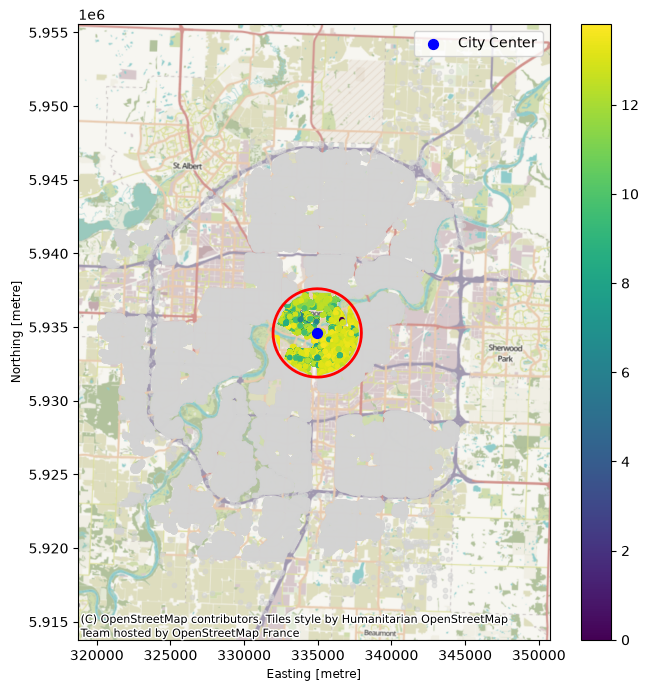

In [ ]:
# homes within 3km of city center

buffer_distance = 3000  # meters
edm_centre_cord_point_projected = edm_centre_cord_point.to_crs(CALC_CRS)
buffer = edm_centre_cord_point_projected.buffer(buffer_distance).iloc[0]
homes_within_buffer = df_ex2[df_ex2.geometry.within(buffer)]
#Plot with color shades
ax = homes_within_buffer.plot(column="Assessed Value", cmap="viridis", legend=True, figsize=(8, 8), markersize=10)
df_ex2[~df_ex2.geometry.within(buffer)].plot(ax=ax, color='lightgray', markersize=10, alpha=0.5)
gpd.GeoSeries(buffer).plot(ax=ax, color='none', edgecolor='red', linewidth=2)
edm_centre_cord_point_projected.plot(ax=ax, color='blue', markersize=50, label='City Center')
# Add nice background map
ctx.add_basemap(ax, crs=CALC_CRS)
plt.legend()

## Example - Airports and Flights

Lastly, we can look at flights. In particular, we can make lines, our other main geometric type. 

Lines often require a bit more data work to get them built, but once done, it works like anything else. 

In [238]:
flights = pd.read_csv("data/flights.csv.zip")
flights = flights[flights["origin"] == "EWR"]
flights = flights[flights["year"] == 2013]
flights.head()

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
5,5,2013,1,1,554.0,558,-4.0,740.0,728,12.0,...,1696,N39463,EWR,ORD,150.0,719,5,58,2013-01-01 05:00:00,United Air Lines Inc.
6,6,2013,1,1,555.0,600,-5.0,913.0,854,19.0,...,507,N516JB,EWR,FLL,158.0,1065,6,0,2013-01-01 06:00:00,JetBlue Airways
13,13,2013,1,1,558.0,600,-2.0,923.0,937,-14.0,...,1124,N53441,EWR,SFO,361.0,2565,6,0,2013-01-01 06:00:00,United Air Lines Inc.
16,16,2013,1,1,559.0,600,-1.0,854.0,902,-8.0,...,1187,N76515,EWR,LAS,337.0,2227,6,0,2013-01-01 06:00:00,United Air Lines Inc.


In [239]:
destA = pd.read_csv("data/Airports_list.csv", encoding='latin-1')
origA = pd.read_csv("data/Airports_list.csv", encoding='latin-1')
origA.head()

,Airport_ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,TZ,Type,Source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789002,20,10,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005,5388,10,U,Pacific/Port_Moresby,airport,OurAirports
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977,239,10,U,Pacific/Port_Moresby,airport,OurAirports
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001,146,10,U,Pacific/Port_Moresby,airport,OurAirports


## Make Data into Geodataframe

We can make lines, but it is annoying and we need to use a shapely helper function to do it. The shapely library is a core library for working with geometric objects, and is used by geopandas under the hood. There are several ways to make lines, but the easiest is to use the shapely helper function `LineString`. We need to provide it with a list of points, and it will make a line out of them.

### Geopandas Data Cleanup and Shapely

Odd data cleanup isn't uncommon with spatial data, especially when it is coming from a source that isn't specifically designed for spatial data. Here, we need to use a shapely helper function to make lines from our origin and destination points. This type of thing may come up, and if so, we can research how to solve our issue. There are a few tools to look at:
<ul>
<li> The shapely library with helpers like this. </li>
<li> The geopandas library, which has some built-in helpers for common tasks. </li>
<li> Well-known Text (WKT) and Well-known Binary (WKB) formats, which are standard ways to represent geometric objects as text or binary data. We can convert them with helpers. </li>
</ul>

In [240]:
from shapely.geometry import LineString
origin = gpd.GeoDataFrame(origA, geometry=gpd.points_from_xy(origA['Longitude'], origA['Latitude']), crs="EPSG:4326")
destination = gpd.GeoDataFrame(destA, geometry=gpd.points_from_xy(destA['Longitude'], destA['Latitude']), crs="EPSG:4326")
flights["path"] = flights.apply(lambda row: LineString([origin.loc[origin['IATA'] == row['origin'], 'geometry'].values[0], destination.loc[destination['IATA'] == row['dest'], 'geometry'].values[0]]), axis=1)
flights_gpd = gpd.GeoDataFrame(flights, geometry="path")
flights_gpd = flights_gpd.set_crs("EPSG:4326", allow_override=True)

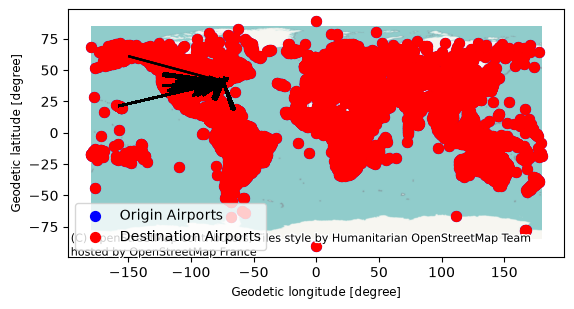

In [241]:
flights_gpd.plot(alpha=0.5, edgecolor='k')
origin.plot(ax=plt.gca(), color='blue', markersize=50, label='Origin Airports')
destination.plot(ax=plt.gca(), color='red', markersize=50, label='Destination Airports')
ctx.add_basemap(plt.gca(), crs=flights_gpd.crs)
plt.legend()

#### Longest Flights

In [242]:
# Join data with both origin and destination airport info,
# based on the IATA code

flights_gpd = flights_gpd.merge(origin, left_on='origin', right_on='IATA', suffixes=('', '_origin'))
flights_gpd = flights_gpd.merge(destination, left_on='dest', right_on='IATA', suffixes=('', '_dest'))

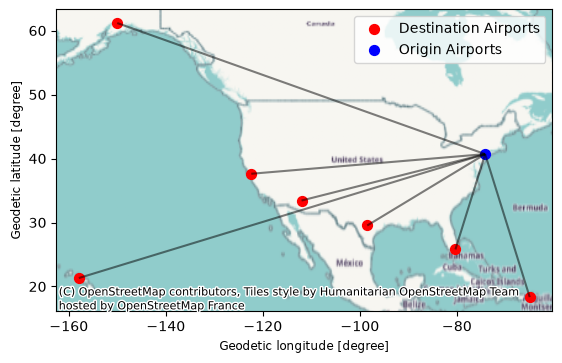

In [243]:
def longestFlightPerTimezone(flights_list, origAirport, destAirport, tz_col= "Timezone_dest"):
    # Group by the specified timezone column and find the longest flight in each group
    longest_flights = flights_list.loc[flights_list.groupby(tz_col)['distance'].idxmax()]
    
    # Merge with origin and destination airport data to get additional information
    longest_flights = longest_flights.merge(origAirport[['IATA', 'geometry']], left_on='origin', right_on='IATA', suffixes=('', '_origin'))
    longest_flights = longest_flights.merge(destAirport[['IATA', 'geometry']], left_on='dest', right_on='IATA', suffixes=('', '_dest2'))
    
    return longest_flights

longest_flights_by_tz = longestFlightPerTimezone(flights_gpd, origin, destination)
longest_flights_by_tz.plot(alpha=0.5, edgecolor='k')
dest_plot_ports = destination[destination['IATA'].isin(longest_flights_by_tz['dest'])]
origin_plot_ports = origin[origin['IATA'].isin(longest_flights_by_tz['origin'])]
dest_plot_ports.plot(ax=plt.gca(), color='red', markersize=50, label='Destination Airports')
origin_plot_ports.plot(ax=plt.gca(), color='blue', markersize=50, label='Origin Airports')

ctx.add_basemap(plt.gca(), crs=longest_flights_by_tz.crs)
plt.legend()

We can also do "shape" stuff to lines. For example, let's make a flight path that is 2 km wide for the flights here.

In [244]:
# list crs of the flights_gpd GeoDataFrame
print("CRS of flights_gpd:", flights_gpd.crs)
print("CRS of origin:", origin.crs)
print("CRS of destination:", destination.crs)

CRS of flights_gpd: EPSG:4326
CRS of origin: EPSG:4326
CRS of destination: EPSG:4326


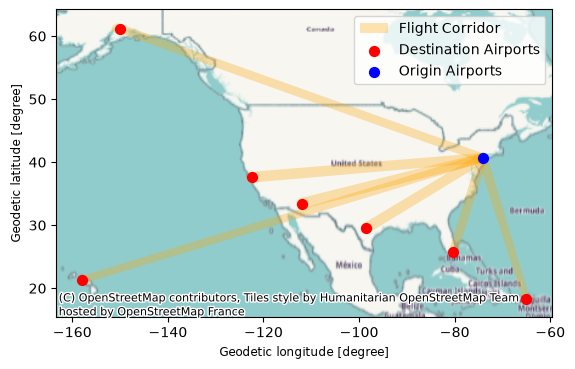

In [245]:
longest_flights_by_tz.to_crs(CALC_CRS, inplace=True)
flight_corridor = longest_flights_by_tz.buffer(100000)  # Buffer of 2 km
flight_corridor = flight_corridor.to_crs("EPSG:4326")  # Convert back to WGS84 for plotting
# plot as above
#longest_flights_by_tz.plot(alpha=0.5, edgecolor='k', figsize=(8, 8))
flight_corridor.plot(color='orange', alpha=0.3, label='Flight Corridor')
dest_plot_ports.plot(ax=plt.gca(), color='red', markersize=50, label='Destination Airports')
origin_plot_ports.plot(ax=plt.gca(), color='blue', markersize=50, label='Origin Airports')
ctx.add_basemap(ax=plt.gca(), crs="EPSG:4326")
plt.legend()

## Exercise  -Airports in Flight Paths